In [1]:
import pandas as pd

df = pd.read_csv("Data/Raw/car data.csv")

df["Car_Name"] = df["Car_Name"].str.strip().str.lower()

motorcycle_patterns = [
    "royal enfield",
    "um renegade",
    "ktm",
    "bajaj",
    "hyosung",
    "yamaha",
    "tvs",
    "hero",
    "suzuki access",
    "honda cb",
    "honda cbr",
    "honda activa",
    "honda dream",
    "honda karizma",
    "honda unicorn",
]

df["Vehicle_Type"] = df["Car_Name"].apply(
    lambda name: "Motorcycle"
    if any(name.startswith(pattern) for pattern in motorcycle_patterns)
    else "Car"
)

print(df["Vehicle_Type"].value_counts())

Vehicle_Type
Car           204
Motorcycle     97
Name: count, dtype: int64


In [2]:
print(df.groupby("Vehicle_Type")["Selling_Price"].describe())

print(
    df.groupby("Vehicle_Type")["Present_Price"].mean()
)

print(
    df.groupby("Vehicle_Type")["Kms_Driven"].median()
)

              count      mean       std   min   25%   50%  75%    max
Vehicle_Type                                                         
Car           204.0  6.571078  5.170514  0.17  3.50  5.25  7.5  35.00
Motorcycle     97.0  0.644845  0.390131  0.10  0.38  0.51  0.9   1.75
Vehicle_Type
Car           10.780000
Motorcycle     1.000515
Name: Present_Price, dtype: float64
Vehicle_Type
Car           39742.5
Motorcycle    18000.0
Name: Kms_Driven, dtype: float64


In [3]:
print(df["Vehicle_Type"].value_counts())

print(df.groupby("Vehicle_Type")["Selling_Price"].describe())

print(df[["Car_Name", "Vehicle_Type"]].drop_duplicates().sort_values("Vehicle_Type").to_string(index=False))

Vehicle_Type
Car           204
Motorcycle     97
Name: count, dtype: int64
              count      mean       std   min   25%   50%  75%    max
Vehicle_Type                                                         
Car           204.0  6.571078  5.170514  0.17  3.50  5.25  7.5  35.00
Motorcycle     97.0  0.644845  0.390131  0.10  0.38  0.51  0.9   1.75
                 Car_Name Vehicle_Type
                     ritz          Car
                      sx4          Car
                     ciaz          Car
                  wagon r          Car
                    swift          Car
            vitara brezza          Car
                  s cross          Car
                 alto 800          Car
                   ertiga          Car
                    dzire          Car
                 alto k10          Car
                    ignis          Car
                      800          Car
                   baleno          Car
                     omni          Car
                 fort

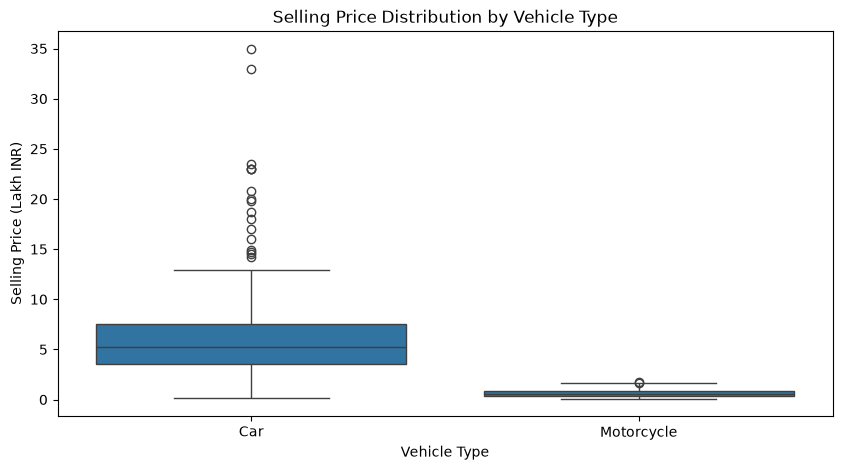

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Vehicle_Type",
    y="Selling_Price"
)

plt.title("Selling Price Distribution by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Selling Price (Lakh INR)")

plt.show()

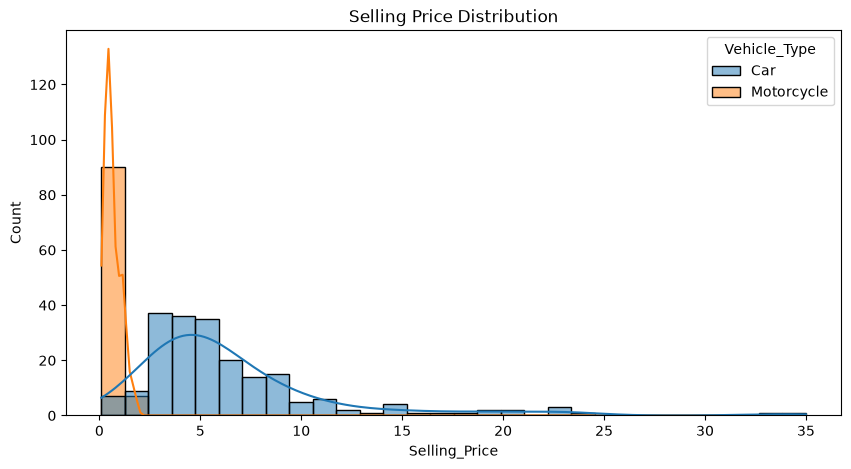

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Selling_Price",
    hue="Vehicle_Type",
    kde=True,
    bins=30
)

plt.title("Selling Price Distribution")
plt.show()